<a href="https://colab.research.google.com/github/JacekDrzycimski/6tunnel/blob/master/Zeta_function_plots_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Riemann Zeta Function Domain Coloring Plot
This notebook demonstrates how to visualize the Riemann zeta function $\zeta(s)$ over the complex plane using domain coloring.

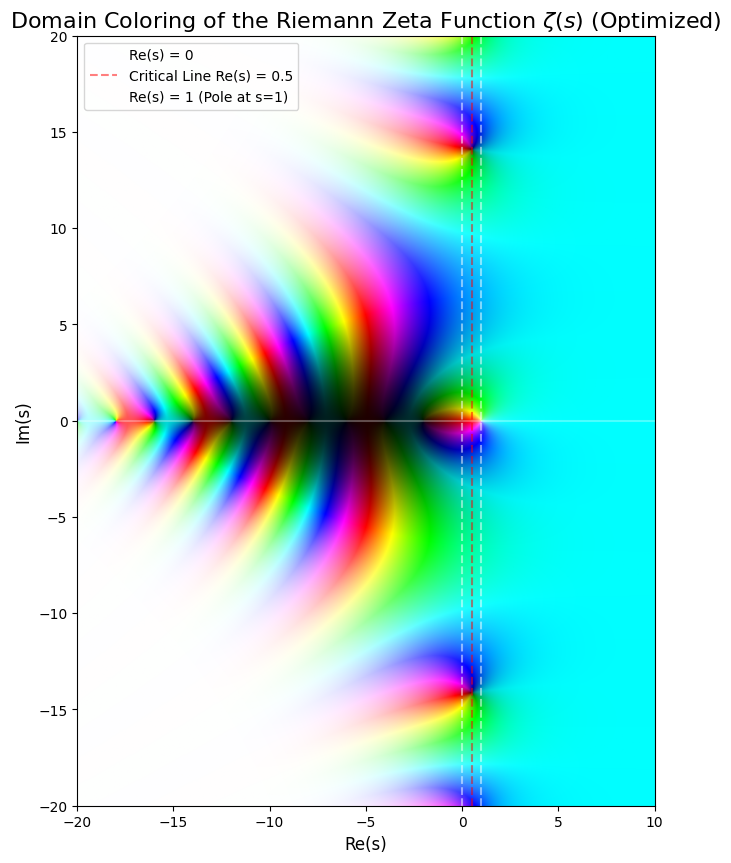

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import zeta

def domain_coloring_vectorized(z):
    """Vectorized mapping of complex numbers to HLS-based RGB values using NumPy."""
    # Phase/Argument determines the Hue (0 to 1)
    h = (np.angle(z) + np.pi) / (2 * np.pi)

    # Magnitude determines the Lightness (brightness)
    r = np.abs(z)
    l = 1.0 - 1.0 / (1.0 + r**0.5)

    # Saturation is kept at 1.0
    s = np.ones_like(z, dtype=float)

    # Vectorized HLS to RGB conversion
    # Since s=1, we can simplify the standard HLS to RGB formulas
    # For s=1, temp2 = l + s - l*s = l + 1 - l = 1 if l < 0.5, or l + s - l*s logic:
    # More generally, let's implement the standard HLS to RGB formula vectorized:

    temp2 = np.where(l < 0.5, l * (1.0 + s), l + s - l * s)
    temp1 = 2.0 * l - temp2

    # Helper to calculate RGB channels
    def tc(t_color):
        t_color = np.where(t_color < 0.0, t_color + 1.0, t_color)
        t_color = np.where(t_color > 1.0, t_color - 1.0, t_color)

        cond1 = t_color < 1.0 / 6.0
        cond2 = t_color < 0.5
        cond3 = t_color < 2.0 / 3.0

        res = np.where(cond1, temp1 + (temp2 - temp1) * 6.0 * t_color,
              np.where(cond2, temp2,
              np.where(cond3, temp1 + (temp2 - temp1) * (2.0 / 3.0 - t_color) * 6.0,
                       temp1)))
        return res

    r_rgb = tc(h + 1.0 / 3.0)
    g_rgb = tc(h)
    b_rgb = tc(h - 1.0 / 3.0)

    # Ensure we handle case where s = 0 (gray), though here s is always 1
    gray_mask = (s == 0.0)
    r_rgb = np.where(gray_mask, l, r_rgb)
    g_rgb = np.where(gray_mask, l, g_rgb)
    b_rgb = np.where(gray_mask, l, b_rgb)

    return np.dstack((r_rgb, g_rgb, b_rgb))

# Define the grid in the complex plane
x = np.linspace(-20, 10, 800)
y = np.linspace(-20, 20, 800)
X, Y = np.meshgrid(x, y)
S = X + 1j * Y

# Calculate Zeta function values
Z = zeta(S)

# Apply optimized domain coloring
img = domain_coloring_vectorized(Z)

# Plot the result
plt.figure(figsize=(12, 10))
plt.imshow(img, extent=[x.min(), x.max(), y.min(), y.max()], origin='lower')
plt.title(r"Domain Coloring of the Riemann Zeta Function $\zeta(s)$ (Optimized)", fontsize=16)
plt.xlabel("Re(s)", fontsize=12)
plt.ylabel("Im(s)", fontsize=12)
plt.axvline(0, color='white', linestyle='--', alpha=0.5, label='Re(s) = 0')
plt.axvline(0.5, color='red', linestyle='--', alpha=0.5, label='Critical Line Re(s) = 0.5')
plt.axvline(1, color='white', linestyle='--', alpha=0.5, label='Re(s) = 1 (Pole at s=1)')
plt.axhline(0, color='white', linestyle='-', alpha=0.3)
plt.legend(loc='upper left')
plt.show()

### Interpretation of the Plot:
- **Trivial Zeros**: You can observe zeros along the negative real axis at $s = -2, -4, -6, \dots$ represented by local color whorls contracting to black.
- **Critical Line**: The red dashed line representing $\text{Re}(s) = 1/2$ is where the non-trivial zeros lie. Along this line, you can spot the points where the colors swirl and converge to black.
- **Pole**: There is a pole at $s = 1$ where the value approaches infinity (represented by white/bright regions surrounding a singular point).